# Classification – will this order be returned?

**Video 9.4** · ShopKart project

**Goal:** Train two classifiers – a Decision Tree and a Logistic Regression – to predict whether an order will be returned, look at predicted probabilities, and spot data leakage.

**How to open in Colab:** go to colab.research.google.com → File → Upload notebook → choose this file. Then click the folder icon on the left and drag these data files in: `shopkart_clean.csv`. Then run cells from top to bottom (Shift + Enter).

## Step 1 – prepare X, y and split (same as Video 9.2)

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("shopkart_clean.csv")

# Target (y): 1 if the order was returned, 0 if kept
y = (df["returned"] == "Y").astype(int)

# Features (X): things we KNOW at the time the order is placed or shipped
features = ["category", "city", "payment_mode", "delivery_days",
            "discount", "membership", "age", "unit_price"]
X = pd.get_dummies(df[features], drop_first=True, dtype=int)   # text columns -> 0/1 columns

# Same split as Video 9.4: 80% train, 20% test, same share of returns in both
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (4000, 23)  Test: (1000, 23)


## Why we do NOT use `rating`
`rating` is given by the customer **after** the order is delivered – often after they have already decided to return it. At the moment we want to predict (when the order ships), the rating does not exist yet.

Using information from the future is called **data leakage**. It makes a model look brilliant in the notebook and useless in real life. We show this at the end of the notebook.

## Step 2 – Decision Tree
A decision tree asks yes/no questions, like a flowchart: *Is city Pune? Is delivery more than 5 days?* `max_depth=4` = at most 4 questions in a row.

In [2]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)

print("Tree accuracy on test:", round(tree.score(X_test, y_test) * 100, 1), "%")
print("Orders predicted 'returned':", tree_pred.sum(), "out of", len(tree_pred))

Tree accuracy on test: 86.1 %
Orders predicted 'returned': 8 out of 1000


In [3]:
# Which features did the tree find most useful?
pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False).head(6).round(3)

city_Pune                  0.420
category_Fashion           0.204
delivery_days              0.113
unit_price                 0.104
age                        0.076
payment_mode_Debit Card    0.046
dtype: float64

## Step 3 – Logistic Regression
Despite the name, this is a **classification** model. It gives each order a probability of being returned between 0 and 1. We put a `StandardScaler` in front of it – this puts age (20–57) and price (₹100–₹20,000) on a similar scale so the model trains smoothly.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

logreg = make_pipeline(StandardScaler(), LogisticRegression())
logreg.fit(X_train, y_train)
log_pred = logreg.predict(X_test)

print("Logistic accuracy on test:", round(logreg.score(X_test, y_test) * 100, 1), "%")
print("Orders predicted 'returned':", log_pred.sum(), "out of", len(log_pred))

Logistic accuracy on test: 86.1 %
Orders predicted 'returned': 2 out of 1000


## Wait – 86% accuracy, but it almost never predicts 'returned'?
Only about 14% of orders are returned. A lazy model that always says "not returned" is right 86% of the time! We look at this trap properly in Video 9.5. For now, let's look at **probabilities** – they are more useful than the yes/no answer.

## Step 4 – predict_proba: the probability of a return

In [5]:
proba = logreg.predict_proba(X_test)[:, 1]     # column 1 = probability of "returned"

look = X_test[["delivery_days", "unit_price", "discount"]].copy()
look["city"] = df.loc[X_test.index, "city"]
look["payment_mode"] = df.loc[X_test.index, "payment_mode"]
look["P(return)"] = proba.round(2)
look["actually returned"] = y_test.values
look.sort_values("P(return)", ascending=False).head(8)

,delivery_days,unit_price,discount,city,payment_mode,P(return),actually returned
61,7,1975,0.0,Pune,COD,0.56,0
1320,6,1519,0.1,Pune,COD,0.55,0
645,8,509,0.2,Pune,Debit Card,0.50,0
2807,8,1830,0.0,Pune,Debit Card,0.49,1
4204,7,1857,0.3,Pune,Credit Card,0.47,1
988,8,2308,0.0,Pune,UPI,0.46,1
4425,8,975,0.2,Pune,Credit Card,0.46,1
122,8,2409,0.1,Pune,UPI,0.45,1


In [6]:
# Do high-probability orders really get returned more? Split test orders into 4 equal groups
look["risk group"] = pd.qcut(look["P(return)"], 4, labels=["Lowest 25%", "Low-mid", "High-mid", "Highest 25%"])
look.groupby("risk group", observed=True)["actually returned"].agg(["count", "mean"]).rename(
    columns={"mean": "actual return rate"}).round(3)

,count,actual return rate
risk group,,
Lowest 25%,285,0.049
Low-mid,219,0.110
High-mid,262,0.156
Highest 25%,234,0.248


**Reading this:** the riskiest quarter of orders is returned several times more often than the safest quarter. So the probabilities DO carry useful information, even though the model rarely crosses the 50% line. ShopKart could, for example, call the riskiest orders before shipping or nudge them away from COD.

## Step 5 – the data leakage trap (what if we add rating?)

In [7]:
X_leak = X.copy()
X_leak["rating"] = df["rating"].fillna(df["rating"].median())
Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    X_leak, y, test_size=0.2, random_state=42, stratify=y)

leaky = DecisionTreeClassifier(max_depth=4, random_state=42).fit(Xl_train, yl_train)
leaky_pred = leaky.predict(Xl_test)
print("Leaky tree accuracy:", round(leaky.score(Xl_test, yl_test) * 100, 1), "%")
print("Returns it catches :", leaky_pred[yl_test.values == 1].sum(), "of", yl_test.sum())
print()
print("Average rating of kept orders    :", round(df.loc[y == 0, "rating"].mean(), 2))
print("Average rating of returned orders:", round(df.loc[y == 1, "rating"].mean(), 2))

Leaky tree accuracy: 90.2 %
Returns it catches : 42 of 137

Average rating of kept orders    : 4.15
Average rating of returned orders: 2.78


The 'leaky' model looks much better – because unhappy customers who return items also give low ratings. But when an order is shipping, **there is no rating yet**, so this model cannot be used. Rule: *only use features you would truly have at the moment you make the prediction.*

## Recap
- Classification predicts a category (returned yes/no)
- Decision Tree = flowchart of questions; Logistic Regression = probability
- `predict_proba` gives a risk score per order
- Never use future information (rating) – that's data leakage

## Bonus (not shown in the video): draw the top of the tree
In the video we read the tree from the board drawing and the importances. This cell draws the real tree's first two levels: the first question is `city_Pune`, then `category_Fashion`.

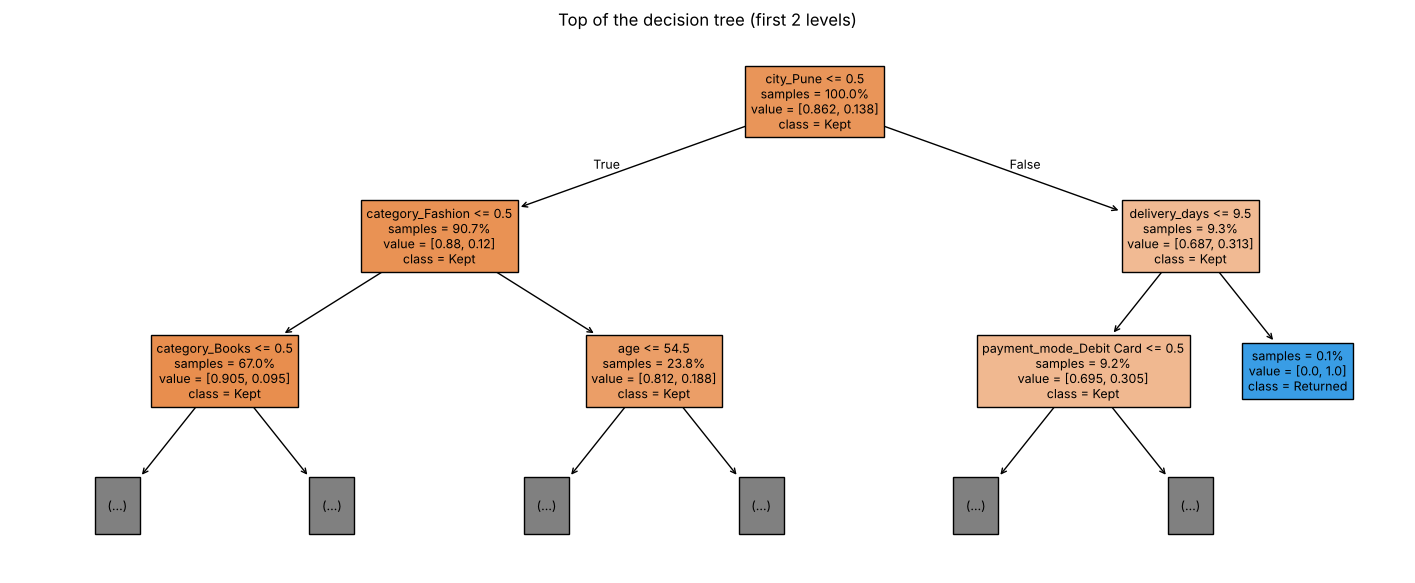

In [8]:
# See the first questions the tree asks
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 7))
plot_tree(tree, feature_names=X.columns, class_names=["Kept", "Returned"],
          filled=True, max_depth=2, fontsize=9, impurity=False, proportion=True)
plt.title("Top of the decision tree (first 2 levels)")
plt.show()